In [17]:
# 1. Imports and configuration

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
DATA_PATH = "powerconsumption.csv"  
MODEL_PATH = "power_consumption_model.joblib"
PREDICTIONS_PATH = "power_consumption_test_predictions.csv"

TARGET_COLUMNS = [
    "PowerConsumption_Zone1",
    "PowerConsumption_Zone2",
    "PowerConsumption_Zone3",
]

WEATHER_COLUMNS = [
    "Temperature",
    "Humidity",
    "WindSpeed",
    "GeneralDiffuseFlows",
    "DiffuseFlows",
]

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

In [18]:
# 2. Load and validate the dataset
df = pd.read_csv("powerconsumption.csv")

required_columns = ["Datetime"] + WEATHER_COLUMNS + TARGET_COLUMNS
missing_columns = [column for column in required_columns if column not in df.columns]
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

print("Original dataset shape:", df.shape)
display(df.head())
display(df.dtypes.rename("dtype").to_frame())

# Parse dates, report data quality, sort chronologically.
df["Datetime"] = pd.to_datetime(df["Datetime"], errors="coerce")
print("\nMissing values before cleaning:")
display(df.isna().sum().to_frame("missing_count"))

print("Exact duplicate rows:", df.duplicated().sum())

# Remove invalid timestamps and exact duplicate rows.
df = df.dropna(subset=["Datetime"]).drop_duplicates()
df = df.sort_values("Datetime").reset_index(drop=True)

# Convert model input/target columns to numeric; invalid values become NaN.
for column in WEATHER_COLUMNS + TARGET_COLUMNS:
    df[column] = pd.to_numeric(df[column], errors="coerce")

print("\nMissing values after type conversion:")
display(df[required_columns].isna().sum().to_frame("missing_count"))

# Drop rows with invalid source values. Missing timestamps are handled below by regularizing
# the timeline, not by inventing weather or consumption values.
df = df.dropna(subset=WEATHER_COLUMNS + TARGET_COLUMNS).reset_index(drop=True)

# Duplicate timestamps can create ambiguous time ordering. Keep the first row and report it.
duplicate_timestamps = df["Datetime"].duplicated().sum()
print("Duplicate timestamps:", duplicate_timestamps)
if duplicate_timestamps:
    df = df.drop_duplicates(subset="Datetime", keep="first").reset_index(drop=True)

# This dataset is sampled every 10 minutes. Reindex to a regular timeline so that lag_6
# really means 1 hour and lag_144 really means 24 hours. Missing intervals remain NaN;
# they are not imputed and rows with unavailable features are removed later.
df = df.set_index("Datetime").sort_index()
regular_index = pd.date_range(
    start=df.index.min(), end=df.index.max(), freq="10min", name="Datetime"
)
df = df.reindex(regular_index).reset_index()

print("\nRegularized dataset shape:", df.shape)
print("Date range:", df["Datetime"].min(), "to", df["Datetime"].max())
print("Missing values including inserted timestamp gaps:")
display(df[required_columns].isna().sum().to_frame("missing_count"))

time_diffs = df["Datetime"].diff().dropna()
print("\nMost common time intervals:")
display(time_diffs.value_counts().head(10).to_frame("count"))

display(df.describe().T)

Original dataset shape: (52416, 9)


,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
0,1/1/2017 0:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,1/1/2017 0:10,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,1/1/2017 0:20,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
3,1/1/2017 0:30,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,1/1/2017 0:40,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964


,dtype
Datetime,str
Temperature,float64
Humidity,float64
WindSpeed,float64
GeneralDiffuseFlows,float64
DiffuseFlows,float64
PowerConsumption_Zone1,float64
PowerConsumption_Zone2,float64
PowerConsumption_Zone3,float64



Missing values before cleaning:


,missing_count
Datetime,0
Temperature,0
Humidity,0
WindSpeed,0
GeneralDiffuseFlows,0
DiffuseFlows,0
PowerConsumption_Zone1,0
PowerConsumption_Zone2,0
PowerConsumption_Zone3,0


...

Duplicate timestamps: 0

Regularized dataset shape: (52416, 9)
Date range: 2017-01-01 00:00:00 to 2017-12-30 23:50:00
Missing values including inserted timestamp gaps:


,missing_count
Datetime,0
Temperature,0
Humidity,0
WindSpeed,0
GeneralDiffuseFlows,0
DiffuseFlows,0
PowerConsumption_Zone1,0
PowerConsumption_Zone2,0
PowerConsumption_Zone3,0



Most common time intervals:


,count
Datetime,
0 days 00:10:00,52415


,count,mean,min,25%,50%,75%,max,std
Datetime,52416,2017-07-01 23:55:00,2017-01-01 00:00:00,2017-04-01 23:57:30,2017-07-01 23:55:00,2017-09-30 23:52:30,2017-12-30 23:50:00,NaN
Temperature,52416.0,18.810024,3.247,14.41,18.78,22.89,40.01,5.815476
Humidity,52416.0,68.259518,11.34,58.31,69.86,81.4,94.8,15.551177
WindSpeed,52416.0,1.959489,0.05,0.078,0.086,4.915,6.483,2.348862
GeneralDiffuseFlows,52416.0,182.696614,0.004,0.062,5.0355,319.6,1163.0,264.40096
DiffuseFlows,52416.0,75.028022,0.011,0.122,4.456,101.0,936.0,124.210949
PowerConsumption_Zone1,52416.0,32344.970564,13895.6962,26310.668692,32265.92034,37309.018185,52204.39512,7130.562564
PowerConsumption_Zone2,52416.0,21042.509082,8560.081466,16980.766032,20823.168405,24713.71752,37408.86076,5201.465892
PowerConsumption_Zone3,52416.0,17835.406218,5935.17407,13129.32663,16415.11747,21624.10042,47598.32636,6622.165099


## 3. Exploratory data analysis

These plots help explain the dataset. They are not used to choose the final model; model selection is based on validation metrics.

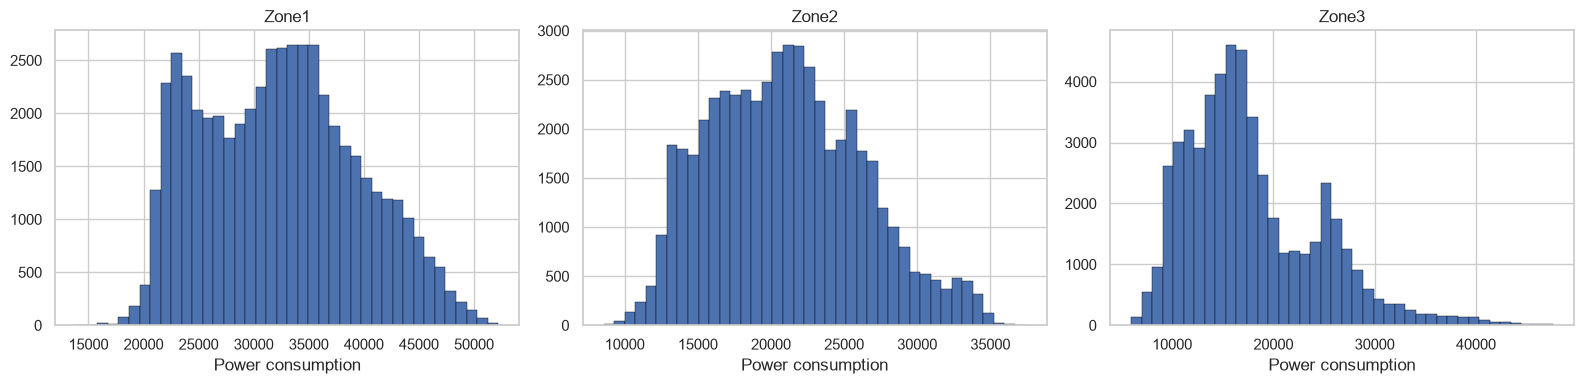

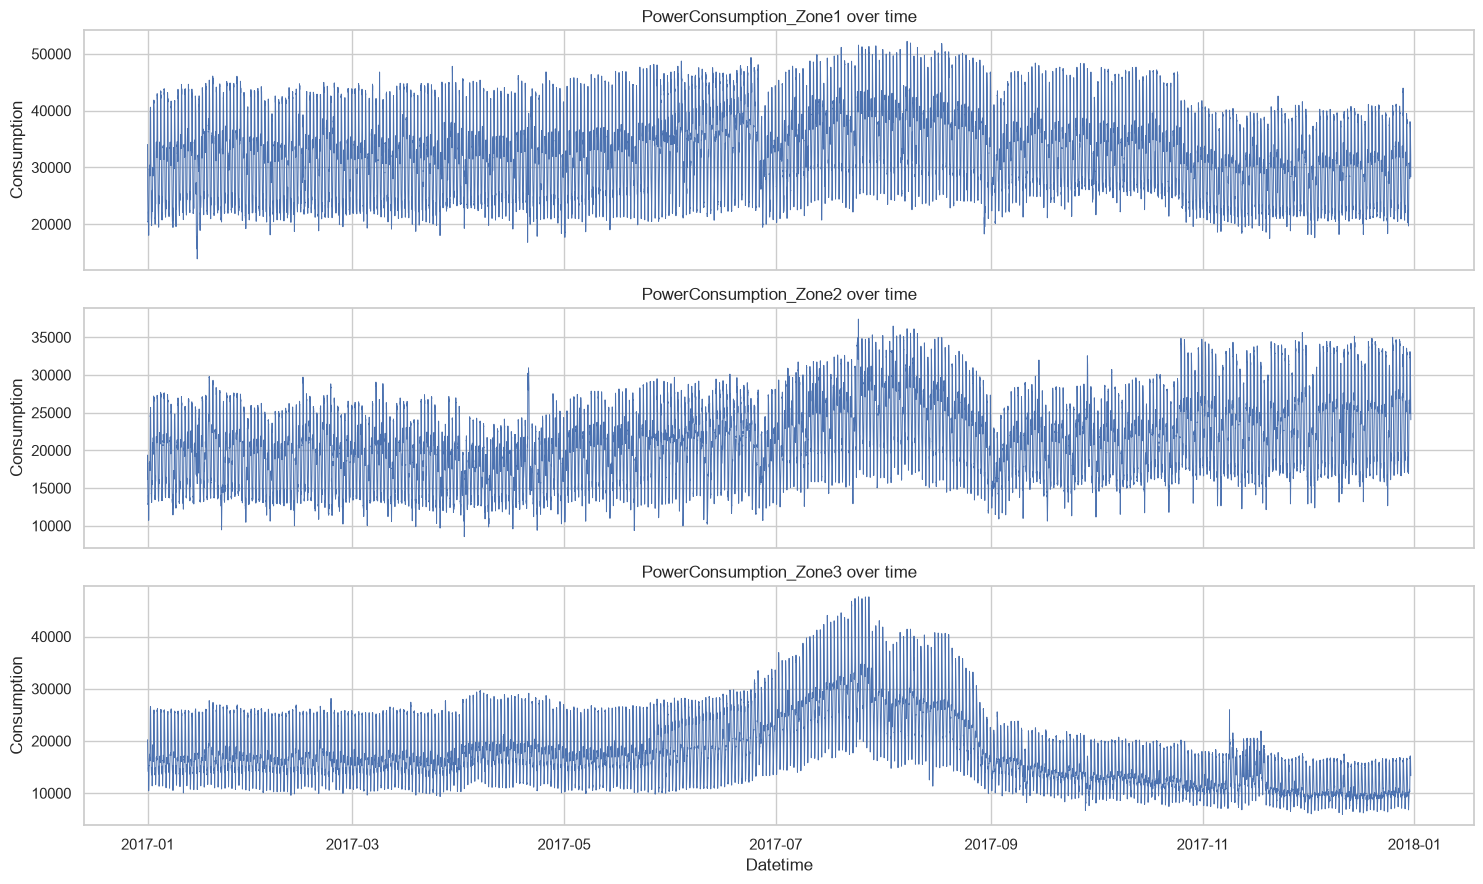

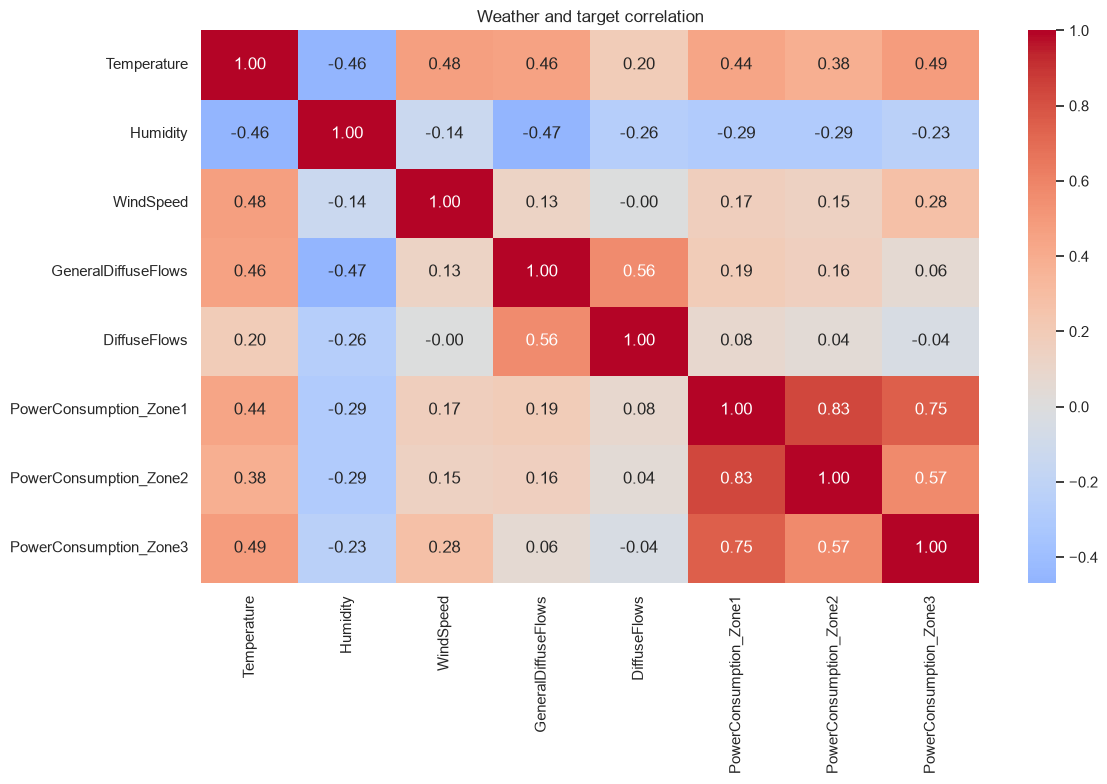

In [19]:
# 3a. Target distributions
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, target in zip(axes, TARGET_COLUMNS):
    ax.hist(df[target], bins=40, edgecolor="black", linewidth=0.3)
    ax.set_title(target.replace("PowerConsumption_", ""))
    ax.set_xlabel("Power consumption")
plt.tight_layout()
plt.show()

# 3b. Power consumption over time
fig, axes = plt.subplots(3, 1, figsize=(15, 9), sharex=True)
for ax, target in zip(axes, TARGET_COLUMNS):
    ax.plot(df["Datetime"], df[target], linewidth=0.7)
    ax.set_title(f"{target} over time")
    ax.set_ylabel("Consumption")
axes[-1].set_xlabel("Datetime")
plt.tight_layout()
plt.show()

# 3c. Numeric correlation heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(df[WEATHER_COLUMNS + TARGET_COLUMNS].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Weather and target correlation")
plt.tight_layout()
plt.show()

## 4. Build leakage-aware features

Each row at time **t** predicts consumption at **t + 10 minutes**.

- Weather values come from time **t** (assumed available when making the prediction).
- Calendar features describe the target timestamp, which is known in advance.
- Lag and rolling features use consumption values at or before time **t** only.
- The target is shifted by one row, so the model never receives the target value for the timestamp it is predicting.

This setup predicts one step ahead. For a longer forecast horizon, the target shift and feature availability assumptions must be changed.

In [20]:
# 4. Create target timestamp and calendar features
work = df.copy()
work["TargetDatetime"] = work["Datetime"].shift(-1)

# Calendar features for the timestamp being predicted
target_time = work["TargetDatetime"]
work["hour"] = target_time.dt.hour
work["day"] = target_time.dt.day
work["month"] = target_time.dt.month
work["dayofweek"] = target_time.dt.dayofweek
work["is_weekend"] = (work["dayofweek"] >= 5).astype(int)

# Cyclic features for periodic patterns
work["hour_sin"] = np.sin(2 * np.pi * work["hour"] / 24)
work["hour_cos"] = np.cos(2 * np.pi * work["hour"] / 24)
work["dayofweek_sin"] = np.sin(2 * np.pi * work["dayofweek"] / 7)
work["dayofweek_cos"] = np.cos(2 * np.pi * work["dayofweek"] / 7)
work["month_sin"] = np.sin(2 * np.pi * (work["month"] - 1) / 12)
work["month_cos"] = np.cos(2 * np.pi * (work["month"] - 1) / 12)

# Past/current consumption features. At row t, shift(0) means the value at t,
# which is already observed when forecasting t+1.
for target in TARGET_COLUMNS:
    short_name = target.replace("PowerConsumption_", "")
    work[f"{short_name}_lag_0"] = work[target]
    work[f"{short_name}_lag_1"] = work[target].shift(1)
    work[f"{short_name}_lag_6"] = work[target].shift(6)       # 1 hour earlier
    work[f"{short_name}_lag_144"] = work[target].shift(144)   # 24 hours earlier
    work[f"{short_name}_rolling_mean_6"] = work[target].rolling(window=6, min_periods=6).mean()
    work[f"{short_name}_rolling_mean_144"] = work[target].rolling(window=144, min_periods=144).mean()

# The next row's target consumption is the prediction target.
for target in TARGET_COLUMNS:
    work[f"target_{target}"] = work[target].shift(-1)

FEATURE_COLUMNS = WEATHER_COLUMNS + [
    "hour", "day", "month", "dayofweek", "is_weekend",
    "hour_sin", "hour_cos", "dayofweek_sin", "dayofweek_cos",
    "month_sin", "month_cos",
]
for target in TARGET_COLUMNS:
    short_name = target.replace("PowerConsumption_", "")
    FEATURE_COLUMNS += [
        f"{short_name}_lag_0",
        f"{short_name}_lag_1",
        f"{short_name}_lag_6",
        f"{short_name}_lag_144",
        f"{short_name}_rolling_mean_6",
        f"{short_name}_rolling_mean_144",
    ]

TARGET_FEATURE_COLUMNS = [f"target_{target}" for target in TARGET_COLUMNS]

# Drop rows where lag/rolling features or next-step targets cannot be formed.
model_data = work.dropna(subset=FEATURE_COLUMNS + TARGET_FEATURE_COLUMNS).reset_index(drop=True)

X = model_data[FEATURE_COLUMNS].astype(float)
y = model_data[TARGET_FEATURE_COLUMNS].copy()
y.columns = TARGET_COLUMNS
prediction_times = model_data["TargetDatetime"].reset_index(drop=True)

print("Feature count:", len(FEATURE_COLUMNS))
print("Modeling rows after lag creation:", len(model_data))
print("X shape:", X.shape, "| y shape:", y.shape)
display(X.head())
display(y.head())

Feature count: 34
Modeling rows after lag creation: 52271
X shape: (52271, 34) | y shape: (52271, 3)


,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,hour,day,month,dayofweek,is_weekend,hour_sin,hour_cos,dayofweek_sin,dayofweek_cos,month_sin,month_cos,Zone1_lag_0,Zone1_lag_1,Zone1_lag_6,Zone1_lag_144,Zone1_rolling_mean_6,Zone1_rolling_mean_144,Zone2_lag_0,Zone2_lag_1,Zone2_lag_6,Zone2_lag_144,Zone2_rolling_mean_6,Zone2_rolling_mean_144,Zone3_lag_0,Zone3_lag_1,Zone3_lag_6,Zone3_lag_144,Zone3_rolling_mean_6,Zone3_rolling_mean_144
0,11.01,75.8,0.076,0.033,0.163,0.0,2.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,26703.79747,27748.86076,32117.46835,34055.69620,29170.632912,28414.177215,18047.41641,18962.91793,21253.49544,16128.87538,19571.428572,17751.114488,17916.14458,18384.57831,20686.26506,20240.96386,19117.108433,17852.650602
1,10.74,77.3,0.078,0.084,0.108,0.0,2.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,26169.11392,26703.79747,31357.97468,29814.68354,28305.822785,28388.860759,17507.59878,18047.41641,20768.38906,19375.07599,19027.963525,17738.145897,17349.39759,17916.14458,20397.10843,20131.08434,18609.156627,17833.333333
2,10.47,78.2,0.078,0.088,0.130,0.0,2.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,25622.27848,26169.11392,30701.77215,29128.10127,27459.240507,28364.514768,17120.97264,17507.59878,20337.99392,19006.68693,18491.793312,17725.050658,16985.06024,17349.39759,19905.54217,19668.43373,18122.409638,17814.698795
3,10.31,79.2,0.076,0.091,0.134,0.0,2.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,24972.15190,25622.27848,29681.01266,28228.86076,26674.430380,28341.898734,16785.41033,17120.97264,19823.70821,18361.09422,17985.410332,17714.108409,16586.02410,16985.06024,19252.04819,18899.27711,17678.072290,17798.634538
4,10.63,79.3,0.079,0.037,0.152,0.0,2.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,24437.46835,24972.15190,28830.37975,27335.69620,25942.278480,28321.772151,16453.49544,16785.41033,19488.14590,17872.34043,17479.635255,17704.255319,16366.26506,16586.02410,18847.22892,18442.40964,17264.578313,17784.216867


,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
0,26169.11392,17507.59878,17349.39759
1,25622.27848,17120.97264,16985.06024
2,24972.15190,16785.41033,16586.02410
3,24437.46835,16453.49544,16366.26506
4,23914.93671,16132.52280,16106.02410


## 5. Chronological train / validation / test split

No random shuffling is used. The newest 15% of records are held out for the final test and are not used for model selection.

In [21]:
n_rows = len(model_data)
train_end = int(n_rows * 0.70)
validation_end = int(n_rows * 0.85)

X_train, y_train = X.iloc[:train_end], y.iloc[:train_end]
X_val, y_val = X.iloc[train_end:validation_end], y.iloc[train_end:validation_end]
X_test, y_test = X.iloc[validation_end:], y.iloc[validation_end:]

test_times = prediction_times.iloc[validation_end:].reset_index(drop=True)

print(f"Train:      {X_train.shape} | {prediction_times.iloc[0]} to {prediction_times.iloc[train_end - 1]}")
print(f"Validation: {X_val.shape} | {prediction_times.iloc[train_end]} to {prediction_times.iloc[validation_end - 1]}")
print(f"Test:       {X_test.shape} | {prediction_times.iloc[validation_end]} to {prediction_times.iloc[-1]}")

Train:      (36589, 34) | 2017-01-02 00:10:00 to 2017-09-13 02:10:00
Validation: (7841, 34) | 2017-09-13 02:20:00 to 2017-11-06 13:00:00
Test:       (7841, 34) | 2017-11-06 13:10:00 to 2017-12-30 23:50:00


## 6. Evaluation helpers and persistence baseline

The persistence baseline predicts the next value as the most recently observed consumption. It is a useful minimum benchmark for short-horizon forecasting.

In [22]:
def calculate_metrics(y_actual, predictions, model_name):
    rows = []
    predictions = np.asarray(predictions)
    for index, target in enumerate(TARGET_COLUMNS):
        actual = y_actual[target].to_numpy()
        predicted = predictions[:, index]
        rows.append({
            "Model": model_name,
            "Target": target,
            "MAE": mean_absolute_error(actual, predicted),
            "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
            "R2": r2_score(actual, predicted),
        })
    return rows

def show_metrics(metrics_df):
    return metrics_df.round({"MAE": 3, "RMSE": 3, "R2": 4})

# Persistence prediction: use the observed consumption at time t to predict t+1.
lag_zero_columns = [f"{target.replace('PowerConsumption_', '')}_lag_0" for target in TARGET_COLUMNS]
baseline_predictions = X_val[lag_zero_columns].to_numpy()
baseline_predictions_df = pd.DataFrame(
    calculate_metrics(y_val, baseline_predictions, "Persistence baseline")
)
display(show_metrics(baseline_predictions_df))

,Model,Target,MAE,RMSE,R2
0,Persistence baseline,PowerConsumption_Zone1,405.031,606.314,0.9915
1,Persistence baseline,PowerConsumption_Zone2,277.566,406.388,0.9923
2,Persistence baseline,PowerConsumption_Zone3,202.701,333.942,0.9890


## 7. Train and compare models

Linear models are scaled using a pipeline. Tree-based models use the original feature values. All models predict the three zones together through multi-output regression where needed.

In [23]:
models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression()),
    ]),
    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0)),
    ]),
    "Lasso": Pipeline([
        ("scaler", StandardScaler()),
        ("model", MultiOutputRegressor(Lasso(alpha=0.001, max_iter=20000))),
    ]),
    "Decision Tree": DecisionTreeRegressor(
        max_depth=12, min_samples_leaf=5, random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=60, min_samples_leaf=2, max_features=0.9,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=60, min_samples_leaf=2, max_features=0.9,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "HistGradientBoosting": MultiOutputRegressor(
        HistGradientBoostingRegressor(
            max_iter=80, learning_rate=0.08, max_leaf_nodes=31,
            random_state=RANDOM_STATE
        )
    ),
}

# Add XGBoost only if it is installed in the current environment.
import importlib.util
if importlib.util.find_spec("xgboost") is not None:
    from xgboost import XGBRegressor
    models["XGBoost"] = MultiOutputRegressor(
        XGBRegressor(
            n_estimators=120,
            learning_rate=0.05,
            max_depth=6,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="reg:squarederror",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )
    )
else:
    print("XGBoost is not installed; skipping it. Install it with: pip install xgboost")

validation_rows = []
fitted_models = {}
validation_predictions = {}

for model_name, model in models.items():
    print(f"Training {model_name}...")
    model.fit(X_train, y_train)
    predictions = model.predict(X_val)
    fitted_models[model_name] = model
    validation_predictions[model_name] = predictions
    validation_rows.extend(calculate_metrics(y_val, predictions, model_name))

validation_metrics = pd.DataFrame(validation_rows)
display(show_metrics(validation_metrics))

Training Linear Regression...
Training Ridge...
Training Lasso...
Training Decision Tree...
Training Random Forest...
Training Extra Trees...
Training HistGradientBoosting...
Training XGBoost...


,Model,Target,MAE,RMSE,R2
0,Linear Regression,PowerConsumption_Zone1,242.909,353.770,0.9971
1,Linear Regression,PowerConsumption_Zone2,173.514,257.506,0.9969
2,Linear Regression,PowerConsumption_Zone3,151.367,237.351,0.9945
3,Ridge,PowerConsumption_Zone1,243.103,354.297,0.9971
4,Ridge,PowerConsumption_Zone2,173.466,257.903,0.9969
5,Ridge,PowerConsumption_Zone3,151.352,237.610,0.9944
6,Lasso,PowerConsumption_Zone1,242.915,353.783,0.9971
7,Lasso,PowerConsumption_Zone2,173.518,257.515,0.9969
8,Lasso,PowerConsumption_Zone3,151.357,237.348,0.9945
9,Decision Tree,PowerConsumption_Zone1,762.851,1052.834,0.9745


## 8. Select the model using validation data only

To avoid allowing the largest-consumption zone to dominate model selection, compute each zone's RMSE divided by that zone's **training-set standard deviation**, then average the three normalized values. Lower is better. The test set is not used here.

In [24]:
target_scales = y_train.std().replace(0, np.nan)

selection_rows = []
for model_name in fitted_models:
    model_metrics = validation_metrics[validation_metrics["Model"] == model_name].set_index("Target")
    normalized_rmse = (model_metrics.loc[TARGET_COLUMNS, "RMSE"] / target_scales[TARGET_COLUMNS]).mean()
    selection_rows.append({
        "Model": model_name,
        "Mean_Normalized_RMSE": normalized_rmse,
        "Mean_MAE": model_metrics.loc[TARGET_COLUMNS, "MAE"].mean(),
        "Mean_RMSE": model_metrics.loc[TARGET_COLUMNS, "RMSE"].mean(),
        "Mean_R2": model_metrics.loc[TARGET_COLUMNS, "R2"].mean(),
    })

selection_table = pd.DataFrame(selection_rows).sort_values("Mean_Normalized_RMSE").reset_index(drop=True)
display(selection_table.round(4))

best_model_name = selection_table.loc[0, "Model"]
print("Selected model based on validation data:", best_model_name)

,Model,Mean_Normalized_RMSE,Mean_MAE,Mean_RMSE,Mean_R2
0,Linear Regression,0.0454,189.2634,282.8758,0.9962
1,Lasso,0.0454,189.2633,282.8821,0.9962
2,Ridge,0.0455,189.3072,283.2703,0.9961
3,HistGradientBoosting,0.0606,248.1697,379.6159,0.9904
4,XGBoost,0.0646,275.9092,405.6211,0.9893
5,Extra Trees,0.2207,916.7009,1310.0083,0.8864
6,Random Forest,0.2271,873.8103,1325.2917,0.8928
7,Decision Tree,0.2590,1056.3281,1517.2744,0.8592


Selected model based on validation data: Linear Regression


## 9. Refit the selected model and evaluate on the test set once

After model selection, refit the selected model on training + validation data. The test data is used only for this final report.

In [25]:
final_model = clone(models[best_model_name])
X_train_final = pd.concat([X_train, X_val], axis=0)
y_train_final = pd.concat([y_train, y_val], axis=0)

final_model.fit(X_train_final, y_train_final)
test_predictions = final_model.predict(X_test)

test_metrics = pd.DataFrame(calculate_metrics(y_test, test_predictions, best_model_name))
print("Final held-out test metrics:")
display(show_metrics(test_metrics))

# Compare test performance with the persistence baseline, without using it for tuning.
test_baseline_predictions = X_test[lag_zero_columns].to_numpy()
test_baseline_metrics = pd.DataFrame(
    calculate_metrics(y_test, test_baseline_predictions, "Persistence baseline")
)
print("Persistence baseline test metrics:")
display(show_metrics(test_baseline_metrics))

Final held-out test metrics:


,Model,Target,MAE,RMSE,R2
0,Linear Regression,PowerConsumption_Zone1,220.207,326.482,0.9971
1,Linear Regression,PowerConsumption_Zone2,188.431,303.184,0.9971
2,Linear Regression,PowerConsumption_Zone3,164.850,278.078,0.9932


Persistence baseline test metrics:


,Model,Target,MAE,RMSE,R2
0,Persistence baseline,PowerConsumption_Zone1,364.421,538.087,0.9921
1,Persistence baseline,PowerConsumption_Zone2,312.532,466.813,0.9930
2,Persistence baseline,PowerConsumption_Zone3,202.773,345.258,0.9895


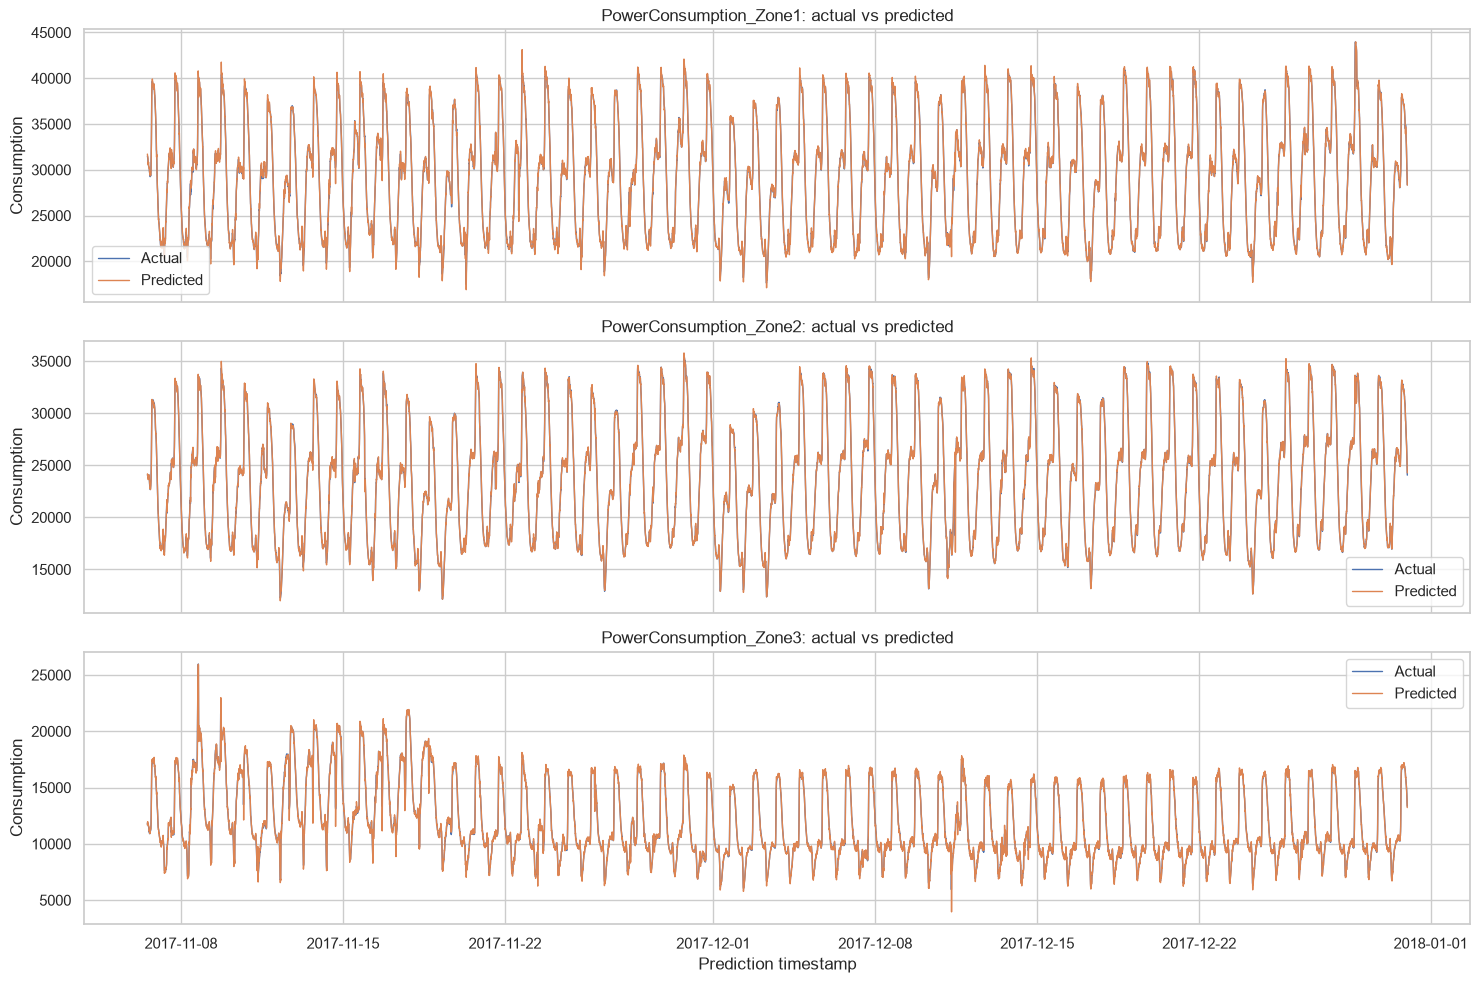

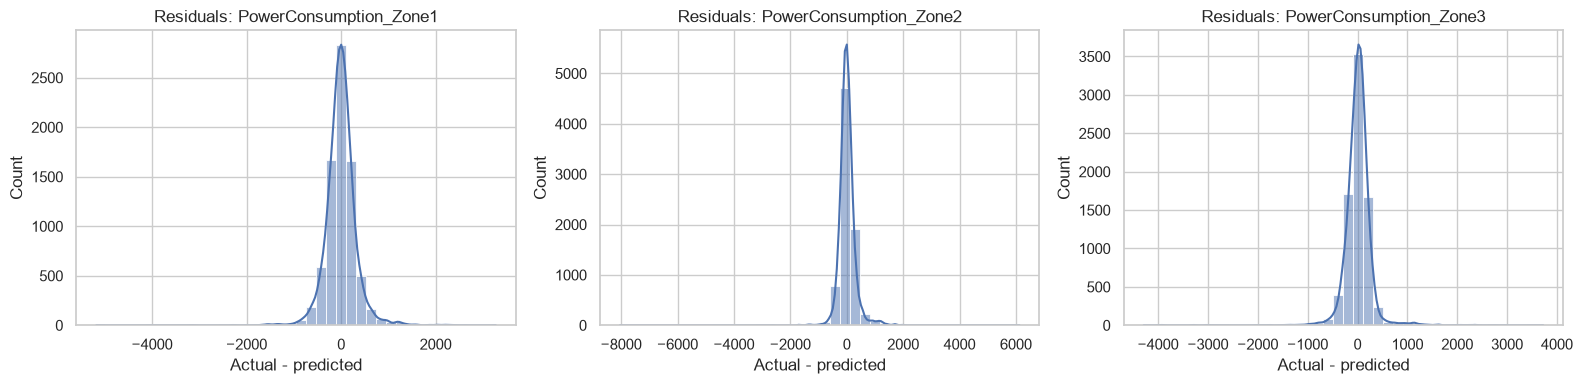

In [26]:
# 10. Actual vs predicted plots for each zone
fig, axes = plt.subplots(3, 1, figsize=(15, 10), sharex=True)
for index, (ax, target) in enumerate(zip(axes, TARGET_COLUMNS)):
    ax.plot(test_times, y_test[target].to_numpy(), label="Actual", linewidth=1)
    ax.plot(test_times, test_predictions[:, index], label="Predicted", linewidth=1)
    ax.set_title(f"{target}: actual vs predicted")
    ax.set_ylabel("Consumption")
    ax.legend()
axes[-1].set_xlabel("Prediction timestamp")
plt.tight_layout()
plt.show()

# Residual plots help reveal systematic prediction errors.
residuals = y_test.to_numpy() - test_predictions
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for index, (ax, target) in enumerate(zip(axes, TARGET_COLUMNS)):
    sns.histplot(residuals[:, index], bins=40, kde=True, ax=ax)
    ax.set_title(f"Residuals: {target}")
    ax.set_xlabel("Actual - predicted")
plt.tight_layout()
plt.show()

## 11. Feature importance / model interpretation

Tree models expose feature importance. For a multi-output estimator, importance is averaged across the three zone-specific estimators. If the selected model is linear, the absolute coefficients are averaged instead. These values show model reliance, not causation.

,Feature,Importance
28,Zone3_lag_0,5138.06194
16,Zone1_lag_0,3342.74332
29,Zone3_lag_1,3075.36427
22,Zone2_lag_0,2733.28839
17,Zone1_lag_1,1184.51337
23,Zone2_lag_1,1122.08321
20,Zone1_rolling_mean_6,296.83685
32,Zone3_rolling_mean_6,295.84187
30,Zone3_lag_6,169.88181
18,Zone1_lag_6,161.16990


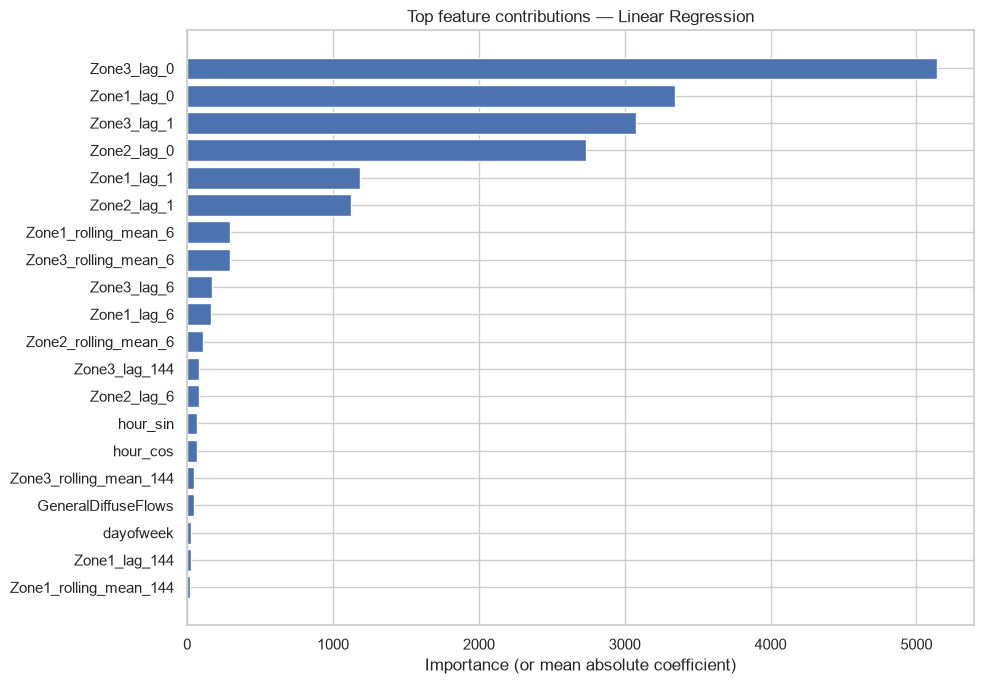

In [27]:
def get_feature_importance(model, feature_names):
    # Pipeline with a final estimator
    if isinstance(model, Pipeline):
        estimator = model.named_steps["model"]
    else:
        estimator = model

    if hasattr(estimator, "estimators_"):
        importances = []
        for sub_estimator in estimator.estimators_:
            if hasattr(sub_estimator, "feature_importances_"):
                importances.append(sub_estimator.feature_importances_)
            elif hasattr(sub_estimator, "coef_"):
                importances.append(np.mean(np.abs(np.atleast_2d(sub_estimator.coef_)), axis=0))
        if importances:
            values = np.mean(importances, axis=0)
        else:
            return None
    elif hasattr(estimator, "feature_importances_"):
        values = estimator.feature_importances_
    elif hasattr(estimator, "coef_"):
        values = np.mean(np.abs(np.atleast_2d(estimator.coef_)), axis=0)
    else:
        return None

    return pd.DataFrame({
        "Feature": feature_names,
        "Importance": values
    }).sort_values("Importance", ascending=False)

feature_importance = get_feature_importance(final_model, FEATURE_COLUMNS)
if feature_importance is not None:
    display(feature_importance.head(20).round(5))
    plt.figure(figsize=(10, 7))
    top_features = feature_importance.head(20).sort_values("Importance")
    plt.barh(top_features["Feature"], top_features["Importance"])
    plt.title(f"Top feature contributions — {best_model_name}")
    plt.xlabel("Importance (or mean absolute coefficient)")
    plt.tight_layout()
    plt.show()
else:
    print("This model does not expose a supported feature-importance measure.")

In [28]:
# 12. Save test predictions and the complete model bundle
prediction_output = pd.DataFrame({
    "TargetDatetime": test_times,
    "Actual_Zone1": y_test[TARGET_COLUMNS[0]].to_numpy(),
    "Predicted_Zone1": test_predictions[:, 0],
    "Actual_Zone2": y_test[TARGET_COLUMNS[1]].to_numpy(),
    "Predicted_Zone2": test_predictions[:, 1],
    "Actual_Zone3": y_test[TARGET_COLUMNS[2]].to_numpy(),
    "Predicted_Zone3": test_predictions[:, 2],
})
prediction_output.to_csv(PREDICTIONS_PATH, index=False)

model_bundle = {
    "model": final_model,
    "model_name": best_model_name,
    "feature_columns": FEATURE_COLUMNS,
    "target_columns": TARGET_COLUMNS,
    "weather_columns": WEATHER_COLUMNS,
    "forecast_horizon": "10 minutes ahead (one row ahead)",
    "lag_definition": {
        "lag_0": "consumption observed at prediction time t",
        "lag_1": "one 10-minute step before t",
        "lag_6": "one hour before t",
        "lag_144": "24 hours before t",
        "rolling_mean_6": "mean of current and previous 5 observations",
        "rolling_mean_144": "mean of current and previous 143 observations",
    },
    "test_metrics": test_metrics.to_dict(orient="records"),
}
joblib.dump(model_bundle, MODEL_PATH)

print("Saved model bundle:", MODEL_PATH)
print("Saved test predictions:", PREDICTIONS_PATH)
display(prediction_output.head())

Saved model bundle: power_consumption_model.joblib
Saved test predictions: power_consumption_test_predictions.csv


,TargetDatetime,Actual_Zone1,Predicted_Zone1,Actual_Zone2,Predicted_Zone2,Actual_Zone3,Predicted_Zone3
0,2017-11-06 13:10:00,31452.30769,31713.901766,24061.98347,24166.732122,11751.32530,11672.480739
1,2017-11-06 13:20:00,31427.69231,31536.324450,24088.01653,24103.432463,11872.77108,11923.786230
2,2017-11-06 13:30:00,31316.92308,31504.585335,24013.63636,24130.018455,11849.63855,11971.145340
3,2017-11-06 13:40:00,31187.69231,31257.050376,24095.45455,23969.742353,11803.37349,11846.711784
4,2017-11-06 13:50:00,30750.76923,31155.452388,23779.33884,24070.636763,11774.45783,11803.697745
